# Welcome to Colab!

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
from io import BytesIO

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

z = zipfile.ZipFile(BytesIO(response.content))
df = None

for name in z.namelist():
    if name.lower().endswith("bank-full.csv"):
        df = pd.read_csv(z.open(name), sep=";")
        break
    elif name.lower().endswith(".zip"):
        inner = zipfile.ZipFile(BytesIO(z.read(name)))
        for file in inner.namelist():
            if file.lower().endswith("bank-full.csv"):
                df = pd.read_csv(inner.open(file), sep=";")
                break
    if df is not None:
        break

if df is None:
    raise FileNotFoundError("bank-full.csv was not found in the official archive.")

print(df.head())
print("Dataset shape:", df.shape)


   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  
Dataset shape: (45211, 17)


In [6]:

print(df.head())
print(df.shape)
df.info()
print(df.describe())


   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  
(45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 

In [7]:

print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Duplicate rows: 0
Shape after removing duplicates: (45211, 17)


y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


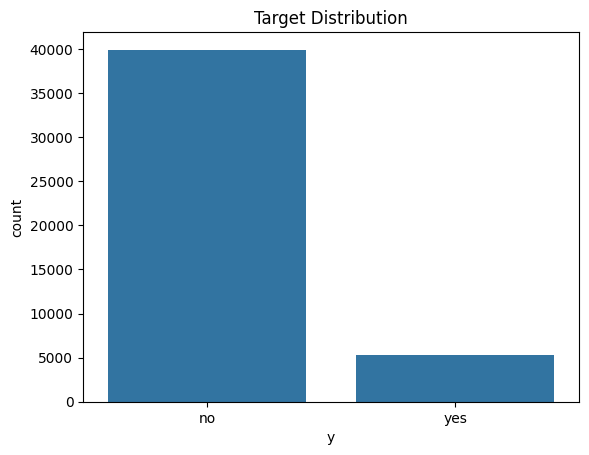

In [8]:

print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="y")
plt.title("Target Distribution")
plt.show()


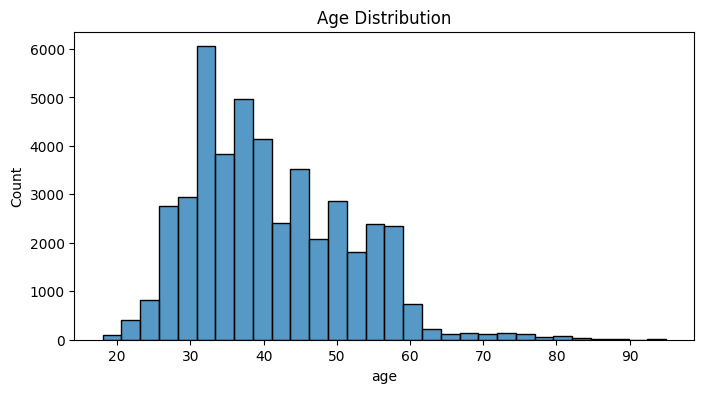

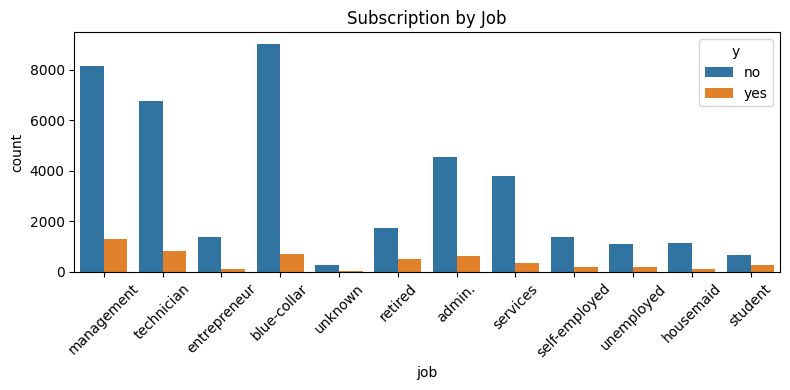

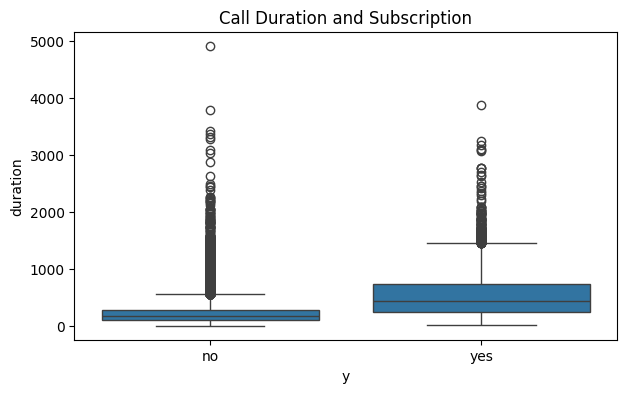

In [9]:

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="age", bins=30)
plt.title("Age Distribution")
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="job", hue="y")
plt.xticks(rotation=45)
plt.title("Subscription by Job")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="y", y="duration")
plt.title("Call Duration and Subscription")
plt.show()


In [10]:

X = df.drop("y", axis=1)
y = df["y"].map({"no": 0, "yes": 1})

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (36168, 16)
Testing shape: (9043, 16)


In [11]:

for col in X_train.columns:
    if X_train[col].dtype == "object":
        value = X_train[col].mode()[0]
        X_train[col] = X_train[col].fillna(value)
        X_test[col] = X_test[col].fillna(value)
    else:
        value = X_train[col].median()
        X_train[col] = X_train[col].fillna(value)
        X_test[col] = X_test[col].fillna(value)

X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

X_train, X_test = X_train.align(
    X_test, join="left", axis=1, fill_value=0
)

print(X_train.shape)
print(X_test.shape)


(36168, 51)
(9043, 51)


In [12]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [13]:

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

results = []


In [14]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

pred = model.predict(X_test_scaled)

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-score": f1_score(y_test, pred, zero_division=0)
})

print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))


              precision    recall  f1-score   support

           0       0.92      0.97      0.95      7985
           1       0.65      0.35      0.45      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.66      0.70      9043
weighted avg       0.89      0.90      0.89      9043

[[7782  203]
 [ 689  369]]


In [15]:

from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-score": f1_score(y_test, pred, zero_division=0)
})

print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))


              precision    recall  f1-score   support

           0       0.92      0.96      0.94      7985
           1       0.61      0.41      0.49      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.69      0.72      9043
weighted avg       0.89      0.90      0.89      9043

[[7704  281]
 [ 625  433]]


In [16]:

from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train_scaled, y_train)

pred = model.predict(X_test_scaled)

results.append({
    "Model": "KNN",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-score": f1_score(y_test, pred, zero_division=0)
})

print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))


              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7985
           1       0.58      0.29      0.39      1058

    accuracy                           0.89      9043
   macro avg       0.74      0.63      0.66      9043
weighted avg       0.87      0.89      0.88      9043

[[7758  227]
 [ 749  309]]


In [17]:

from sklearn.svm import SVC

sample_size = min(10000, len(y_train))
sample = np.random.RandomState(42).choice(
    len(y_train), sample_size, replace=False
)

model = SVC(kernel="rbf")
model.fit(X_train_scaled[sample], y_train.iloc[sample])

pred = model.predict(X_test_scaled)

results.append({
    "Model": "SVM (RBF)",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-score": f1_score(y_test, pred, zero_division=0)
})

print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))


              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7985
           1       0.66      0.29      0.40      1058

    accuracy                           0.90      9043
   macro avg       0.79      0.64      0.67      9043
weighted avg       0.88      0.90      0.88      9043

[[7830  155]
 [ 751  307]]


In [18]:

from sklearn.ensemble import BaggingClassifier

model = BaggingClassifier(
    n_estimators=30,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

results.append({
    "Model": "Bagging",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-score": f1_score(y_test, pred, zero_division=0)
})

print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))


              precision    recall  f1-score   support

           0       0.93      0.96      0.95      7985
           1       0.62      0.46      0.53      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.71      0.74      9043
weighted avg       0.89      0.90      0.90      9043

[[7691  294]
 [ 574  484]]


In [19]:

from sklearn.ensemble import AdaBoostClassifier

model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

results.append({
    "Model": "AdaBoost",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-score": f1_score(y_test, pred, zero_division=0)
})

print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))


              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7985
           1       0.60      0.31      0.41      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.64      0.68      9043
weighted avg       0.88      0.90      0.88      9043

[[7765  220]
 [ 727  331]]


In [20]:

from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train_scaled.shape[1])
print("PCA components:", X_train_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())


Original features: 51
PCA components: 36
Explained variance: 0.9510468942652465


In [21]:

model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)

pred = model.predict(X_test_pca)

results.append({
    "Model": "Logistic Regression + PCA",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1-score": f1_score(y_test, pred, zero_division=0)
})

print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))


              precision    recall  f1-score   support

           0       0.92      0.97      0.95      7985
           1       0.64      0.34      0.44      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.66      0.69      9043
weighted avg       0.89      0.90      0.89      9043

[[7783  202]
 [ 699  359]]


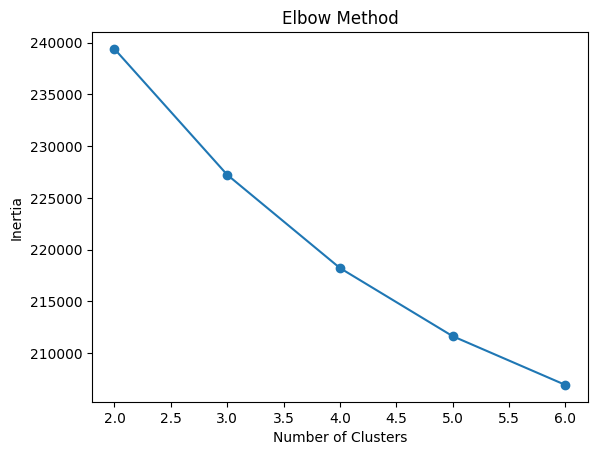

In [22]:

from sklearn.cluster import KMeans

cluster_sample = X_train_scaled[
    np.random.RandomState(42).choice(
        len(X_train_scaled),
        min(5000, len(X_train_scaled)),
        replace=False
    )
]

inertia = []

for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(cluster_sample)
    inertia.append(km.inertia_)

plt.plot(range(2, 7), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


Cluster
0    17536
1    12051
2     6581
Name: count, dtype: int64
Cluster
0    41.486656
1    40.019998
2    40.909740
Name: age, dtype: float64


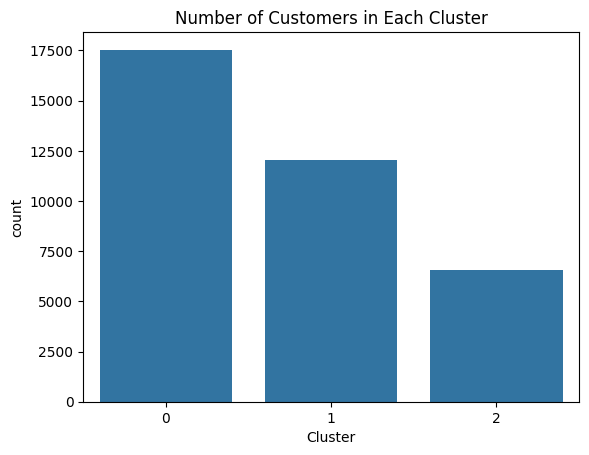

In [23]:

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_train_scaled)

cluster_data = df.loc[X_train.index].copy()
cluster_data["Cluster"] = clusters

print(cluster_data["Cluster"].value_counts().sort_index())
print(cluster_data.groupby("Cluster")["age"].mean())

sns.countplot(data=cluster_data, x="Cluster")
plt.title("Number of Customers in Each Cluster")
plt.show()


In [24]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

print(results_df.round(3))


                       Model  Accuracy  Precision  Recall  F1-score
0                    Bagging     0.904      0.622   0.457     0.527
1              Decision Tree     0.900      0.606   0.409     0.489
2        Logistic Regression     0.901      0.645   0.349     0.453
3  Logistic Regression + PCA     0.900      0.640   0.339     0.443
4                   AdaBoost     0.895      0.601   0.313     0.411
5                  SVM (RBF)     0.900      0.665   0.290     0.404
6                        KNN     0.892      0.576   0.292     0.388


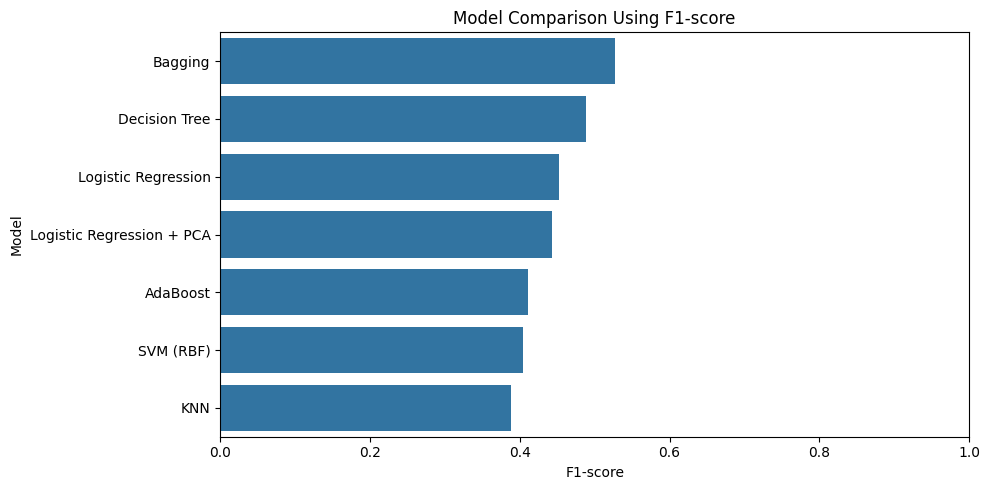

In [25]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="F1-score",
    y="Model"
)

plt.title("Model Comparison Using F1-score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


Best model based on F1-score:
Bagging

Best model results:
Model         Bagging
Accuracy     0.904014
Precision    0.622108
Recall       0.457467
F1-score     0.527233
Name: 0, dtype: object


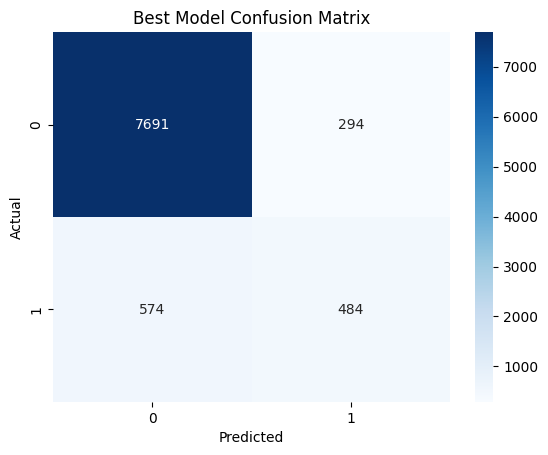

              precision    recall  f1-score   support

           0       0.93      0.96      0.95      7985
           1       0.62      0.46      0.53      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.71      0.74      9043
weighted avg       0.89      0.90      0.90      9043



In [26]:

print("Best model based on F1-score:")
print(results_df.iloc[0]["Model"])

print("\nBest model results:")
print(results_df.iloc[0])

best_name = results_df.iloc[0]["Model"]

if best_name == "Logistic Regression":
    best_model = LogisticRegression(max_iter=1000)
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)

elif best_name == "Decision Tree":
    best_model = DecisionTreeClassifier(max_depth=10, random_state=42)
    best_model.fit(X_train, y_train)
    best_pred = best_model.predict(X_test)

elif best_name == "KNN":
    best_model = KNeighborsClassifier(n_neighbors=5)
    best_model.fit(X_train_scaled, y_train)
    best_pred = best_model.predict(X_test_scaled)

elif best_name == "SVM (RBF)":
    best_model = SVC(kernel="rbf")
    best_model.fit(X_train_scaled[sample], y_train.iloc[sample])
    best_pred = best_model.predict(X_test_scaled)

elif best_name == "Bagging":
    best_model = BaggingClassifier(n_estimators=30, random_state=42, n_jobs=-1)
    best_model.fit(X_train, y_train)
    best_pred = best_model.predict(X_test)

elif best_name == "AdaBoost":
    best_model = AdaBoostClassifier(n_estimators=50, random_state=42)
    best_model.fit(X_train, y_train)
    best_pred = best_model.predict(X_test)

else:
    best_model = LogisticRegression(max_iter=1000)
    best_model.fit(X_train_pca, y_train)
    best_pred = best_model.predict(X_test_pca)

cm = confusion_matrix(y_test, best_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Best Model Confusion Matrix")
plt.show()

print(classification_report(y_test, best_pred, zero_division=0))
